<a href="https://colab.research.google.com/github/ANJARRIZANDI/simuteh-2330511035/blob/main/notebook/B3_histogram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%cd /content/simuteh-2330511035/notebook

/content/simuteh-2330511035/notebook


teh_041.png {'rerata': 178.1, 'simpangan_baku': 40.7, 'min': 70, 'maks': 217, 'persen_gelap': 0.0, 'persen_terang': 3.1}
teh_042.png {'rerata': 135.8, 'simpangan_baku': 43.4, 'min': 12, 'maks': 184, 'persen_gelap': 12.7, 'persen_terang': 0.0}
teh_043.png {'rerata': 211.2, 'simpangan_baku': 25.7, 'min': 143, 'maks': 243, 'persen_gelap': 0.0, 'persen_terang': 77.3}
teh_044.png {'rerata': 156.7, 'simpangan_baku': 14.3, 'min': 99, 'maks': 198, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 125.7, 'simpangan_baku': 53.8, 'min': 24, 'maks': 252, 'persen_gelap': 0.9, 'persen_terang': 12.7}


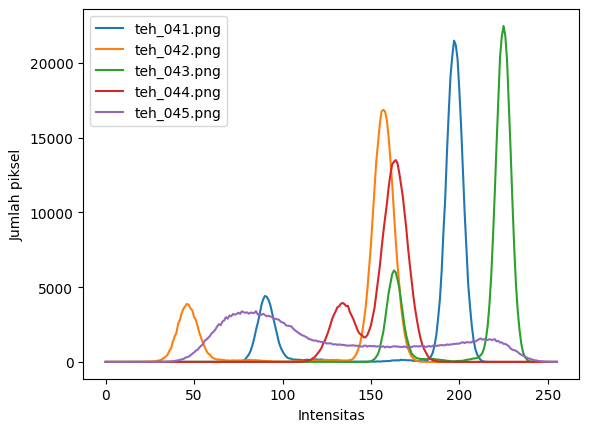

In [7]:
from utils_cv import statistik

for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:

    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
                        cv2.COLOR_BGR2GRAY)

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")
plt.show()

In [11]:
import sys

sys.path.append("../src")

from utils_cv import kontras_bercak

print("Fungsi kontras_bercak berhasil diimpor!")

Fungsi kontras_bercak berhasil diimpor!


In [12]:
# Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE
nama = "teh_045.png"                 # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))      # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0,
                             tileGridSize=(8, 8)).apply(gray),
}
for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "f"sigma={c.std():.1f}")


asli       KB=2.01 sigma=53.8
negatif    KB=2.01 sigma=53.8
cerah+50   KB=2.01 sigma=50.6
kontras    KB=2.01 sigma=73.0
regang     KB=2.06 sigma=77.5
gamma0.5   KB=1.76 sigma=37.8
gamma1.8   KB=2.46 sigma=60.2
ekualisasi KB=1.53 sigma=73.4
CLAHE      KB=2.21 sigma=46.2


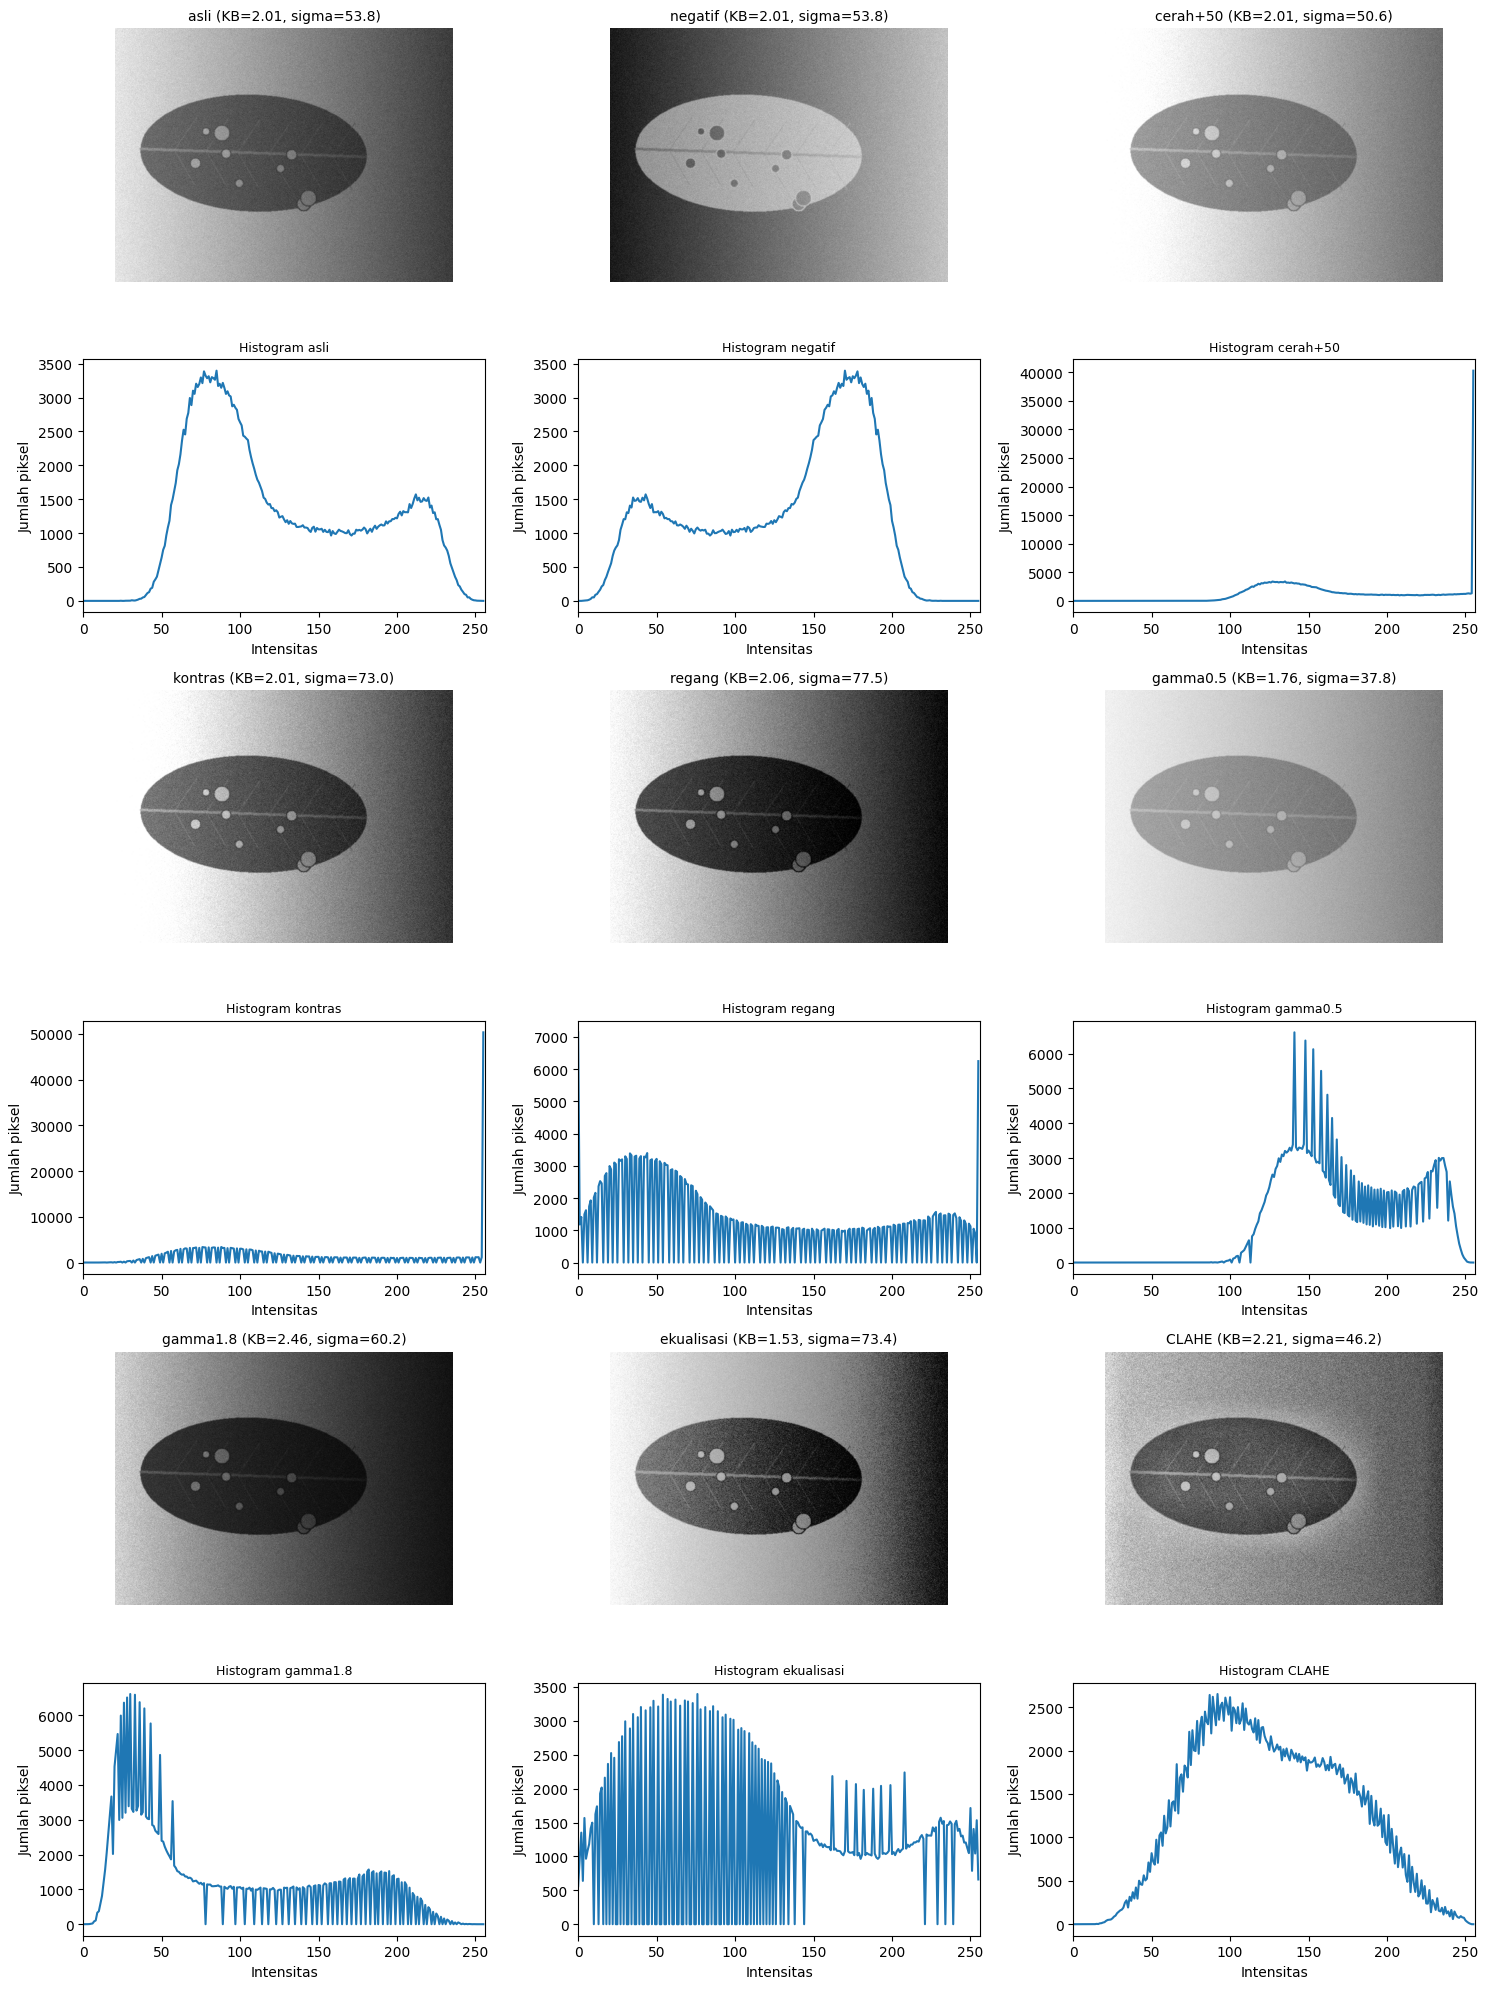

In [13]:
# Langkah 3.3 - Visualisasi citra dan histogram hasil perbaikan

fig, axes = plt.subplots(6, 3, figsize=(15, 20))

for i, (nm, c) in enumerate(hasil.items()):

    baris = (i // 3) * 2
    kolom = i % 3

    # Menghitung KB dan simpangan baku
    kb = kontras_bercak(c, md, mb)
    sigma = c.std()

    # Menampilkan citra hasil perbaikan
    axes[baris, kolom].imshow(c, cmap="gray", vmin=0, vmax=255)
    axes[baris, kolom].set_title(
        f"{nm} (KB={kb:.2f}, sigma={sigma:.1f})",
        fontsize=10
    )
    axes[baris, kolom].axis("off")

    # Menghitung dan menampilkan histogram
    hist = cv2.calcHist([c], [0], None, [256], [0, 256])

    axes[baris + 1, kolom].plot(hist)
    axes[baris + 1, kolom].set_title(f"Histogram {nm}", fontsize=9)
    axes[baris + 1, kolom].set_xlabel("Intensitas")
    axes[baris + 1, kolom].set_ylabel("Jumlah piksel")
    axes[baris + 1, kolom].set_xlim([0, 256])

plt.tight_layout()

plt.savefig(
    "../hasil/b3_perbaikan_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Kode 3.3 Eksperimen CLAHE

# eksperimen parameter CLAHE
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        ).apply(gray)

        print(
            f"clip={clip} tile={tile}: "
            f"KB={kontras_bercak(c, md, mb):.2f}"
        )

clip=1.0 tile=4: KB=2.62
clip=1.0 tile=8: KB=2.47
clip=1.0 tile=16: KB=2.33
clip=2.0 tile=4: KB=2.49
clip=2.0 tile=8: KB=2.21
clip=2.0 tile=16: KB=2.08
clip=4.0 tile=4: KB=2.10
clip=4.0 tile=8: KB=1.80
clip=4.0 tile=16: KB=1.61


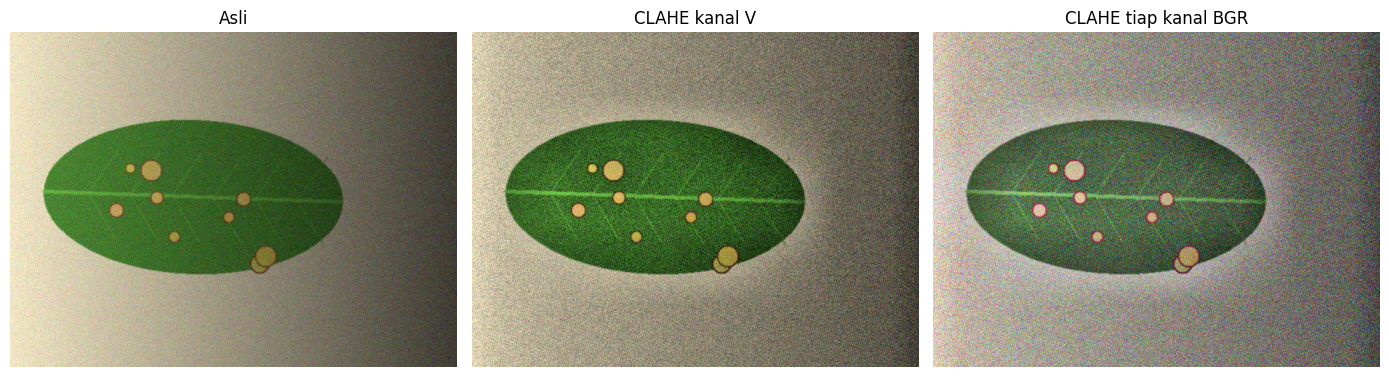

In [16]:
# CLAHE pada citra warna: kanal V dan tiap kanal BGR

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])

via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

via_bgr = cv2.merge([
    clahe.apply(c) for c in cv2.split(img)
])

tampil(
    [img, via_v, via_bgr],
    ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]
)

In [18]:
# Fungsi perbaikan citra untuk Langkah 3.5

def perbaikan_citra(gray, metode):

    if metode == "gamma0.5":
        lut = np.array([
            255 * (i / 255) ** 0.5 for i in range(256)
        ])
        return cv2.LUT(gray, lut.clip(0, 255).astype(np.uint8))

    elif metode == "gamma1.8":
        lut = np.array([
            255 * (i / 255) ** 1.8 for i in range(256)
        ])
        return cv2.LUT(gray, lut.clip(0, 255).astype(np.uint8))

    elif metode == "regang":
        rmin, rmax = np.percentile(gray, (2, 98))

        if rmax <= rmin:
            return gray.copy()

        return np.clip(
            (gray.astype(np.float32) - rmin) /
            (rmax - rmin) * 255,
            0, 255
        ).astype(np.uint8)

    elif metode == "CLAHE":
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        return clahe.apply(gray)

In [19]:
# Langkah 3.5 - Perbaikan citra kelas berat dan ringan

daftar_uji = [
    ("Gelap", "teh_042.png", "teh_022.png", "gamma0.5"),
    ("Terang", "teh_043.png", "teh_023.png", "gamma1.8"),
    ("Kontras rendah", "teh_044.png", "teh_024.png", "regang"),
    ("Bayangan", "teh_045.png", "teh_025.png", "CLAHE")
]

hasil_b35 = []

for kondisi, berat, ringan, metode in daftar_uji:

    for kelas, nama in [
        ("Berat", berat),
        ("Ringan", ringan)
    ]:

        img = baca(f"../data/sintetis/citra/{nama}")

        md = cv2.imread(
            f"../data/sintetis/mask_daun/{nama}", 0
        )

        mb = cv2.imread(
            f"../data/sintetis/mask_bercak/{nama}", 0
        )

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        perbaikan = perbaikan_citra(gray, metode)

        kb_asli = kontras_bercak(gray, md, mb)
        kb_perbaikan = kontras_bercak(perbaikan, md, mb)

        hasil_b35.append({
            "Kondisi": kondisi,
            "Kelas": kelas,
            "Nama citra": nama,
            "Metode": metode,
            "KB asli": round(kb_asli, 2),
            "KB perbaikan": round(kb_perbaikan, 2)
        })

        print(
            f"{nama} | {kelas} | {metode} | "
            f"KB asli={kb_asli:.2f} | "
            f"KB perbaikan={kb_perbaikan:.2f}"
        )

tabel_b35 = pd.DataFrame(hasil_b35)

display(tabel_b35)

tabel_b35.to_csv(
    "../hasil/b3_perbaikan_empat_kondisi.csv",
    index=False
)

teh_042.png | Berat | gamma0.5 | KB asli=5.42 | KB perbaikan=4.36
teh_022.png | Ringan | gamma0.5 | KB asli=3.14 | KB perbaikan=2.43
teh_043.png | Berat | gamma1.8 | KB asli=5.08 | KB perbaikan=5.47
teh_023.png | Ringan | gamma1.8 | KB asli=4.26 | KB perbaikan=4.70
teh_044.png | Berat | regang | KB asli=1.74 | KB perbaikan=1.86
teh_024.png | Ringan | regang | KB asli=0.85 | KB perbaikan=0.92
teh_045.png | Berat | CLAHE | KB asli=2.01 | KB perbaikan=2.21
teh_025.png | Ringan | CLAHE | KB asli=1.12 | KB perbaikan=1.27


,Kondisi,Kelas,Nama citra,Metode,KB asli,KB perbaikan
0,Gelap,Berat,teh_042.png,gamma0.5,5.42,4.36
1,Gelap,Ringan,teh_022.png,gamma0.5,3.14,2.43
2,Terang,Berat,teh_043.png,gamma1.8,5.08,5.47
3,Terang,Ringan,teh_023.png,gamma1.8,4.26,4.70
4,Kontras rendah,Berat,teh_044.png,regang,1.74,1.86
5,Kontras rendah,Ringan,teh_024.png,regang,0.85,0.92
6,Bayangan,Berat,teh_045.png,CLAHE,2.01,2.21
7,Bayangan,Ringan,teh_025.png,CLAHE,1.12,1.27


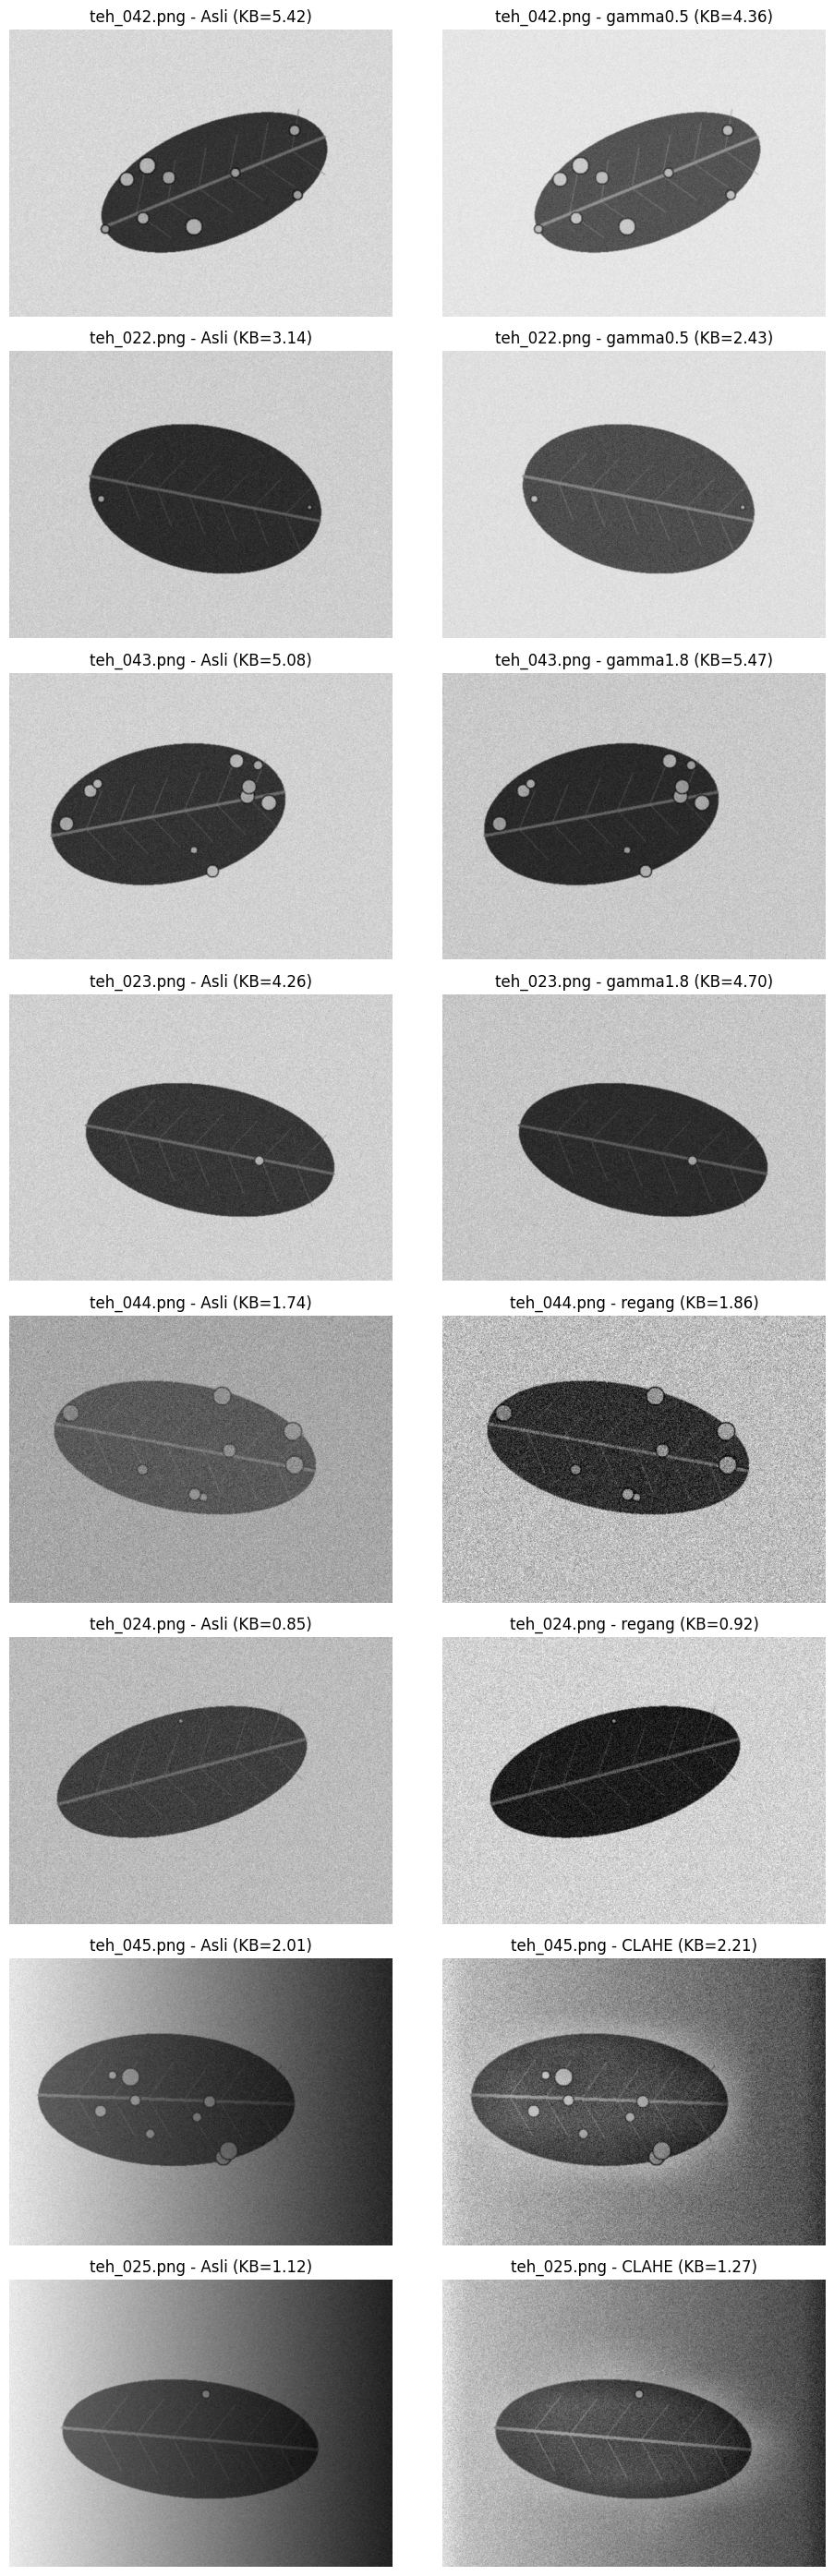

In [20]:
# Visualisasi sebelum dan sesudah perbaikan

fig, axes = plt.subplots(8, 2, figsize=(10, 28))

baris = 0

for kondisi, berat, ringan, metode in daftar_uji:

    for kelas, nama in [
        ("Berat", berat),
        ("Ringan", ringan)
    ]:

        img = baca(f"../data/sintetis/citra/{nama}")
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        md = cv2.imread(
            f"../data/sintetis/mask_daun/{nama}", 0
        )
        mb = cv2.imread(
            f"../data/sintetis/mask_bercak/{nama}", 0
        )

        perbaikan = perbaikan_citra(gray, metode)

        kb_asli = kontras_bercak(gray, md, mb)
        kb_baru = kontras_bercak(perbaikan, md, mb)

        axes[baris, 0].imshow(gray, cmap="gray")
        axes[baris, 0].set_title(
            f"{nama} - Asli (KB={kb_asli:.2f})"
        )
        axes[baris, 0].axis("off")

        axes[baris, 1].imshow(perbaikan, cmap="gray")
        axes[baris, 1].set_title(
            f"{nama} - {metode} (KB={kb_baru:.2f})"
        )
        axes[baris, 1].axis("off")

        baris += 1

plt.tight_layout()

plt.savefig(
    "../hasil/b3_perbaikan_empat_kondisi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()